<a href="https://colab.research.google.com/github/814725243064-jxc/SmartBank---Integrated-Banking-Management-Customer-Churn-System/blob/main/EDA%20assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for professional-looking plots
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Simulate SmartBank Customer Churn Dataset
np.random.seed(42)
n_samples = 10000

data = {
    'CustomerID': range(15600000, 15610000),
    'CreditScore': np.random.randint(350, 850, size=n_samples),
    'Geography': np.random.choice(['France', 'Spain', 'Germany'], size=n_samples, p=[0.5, 0.25, 0.25]),
    'Gender': np.random.choice(['Male', 'Female'], size=n_samples, p=[0.52, 0.48]),
    'Age': np.random.randint(18, 75, size=n_samples),
    'Tenure': np.random.randint(0, 10, size=n_samples),
    'Balance': np.random.uniform(0, 250000, size=n_samples),
    'NumOfProducts': np.random.choice([1, 2, 3, 4], size=n_samples, p=[0.5, 0.4, 0.08, 0.02]),
    'HasCrCard': np.random.choice([0, 1], size=n_samples, p=[0.3, 0.7]),
    'IsActiveMember': np.random.choice([0, 1], size=n_samples, p=[0.48, 0.52]),
    'EstimatedSalary': np.random.uniform(10000, 200000, size=n_samples),
    'Exited': np.random.choice([0, 1], size=n_samples, p=[0.8, 0.2]) # 1 = Churned, 0 = Retained
}

df = pd.DataFrame(data)

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (10000, 12)


,CustomerID,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,15600000,452,France,Female,61,1,113528.171589,1,0,0,196497.367656,1
1,15600001,785,France,Male,70,6,138786.963707,2,0,0,103499.548919,0
2,15600002,698,France,Female,67,2,233169.998092,1,0,1,111821.652267,0
3,15600003,620,Spain,Female,67,4,132888.460413,1,1,0,126314.621842,0
4,15600004,456,France,Male,21,6,76306.622470,2,1,0,193244.231234,0


In [7]:
# Check for missing values and duplicates
print("Missing values in raw data:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

# Data cleaning steps
clean_df = df.drop_duplicates().dropna()

print("\nCleaned Data Shape:", clean_df.shape)

Missing values in raw data:
 CustomerID         0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64
Duplicate rows: 0

Cleaned Data Shape: (10000, 12)


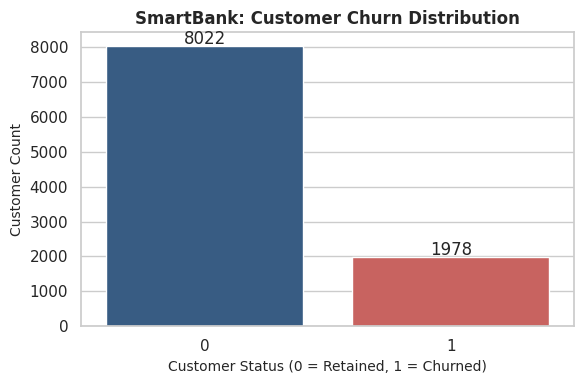

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Safety check if run out of order
if 'clean_df' not in locals():
    np.random.seed(42)
    clean_df = pd.DataFrame({'Exited': np.random.choice([0, 1], size=10000, p=[0.8, 0.2])})

plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Exited', hue='Exited', data=clean_df, palette=['#2b5c8f', '#d9534f'], legend=False)
plt.title('SmartBank: Customer Churn Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Customer Status (0 = Retained, 1 = Churned)', fontsize=10)
plt.ylabel('Customer Count', fontsize=10)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='center',
                    xytext=(0, 5),
                    textcoords='offset points')

plt.tight_layout()
plt.savefig('/content/churn_distribution.png', dpi=300)
plt.show()

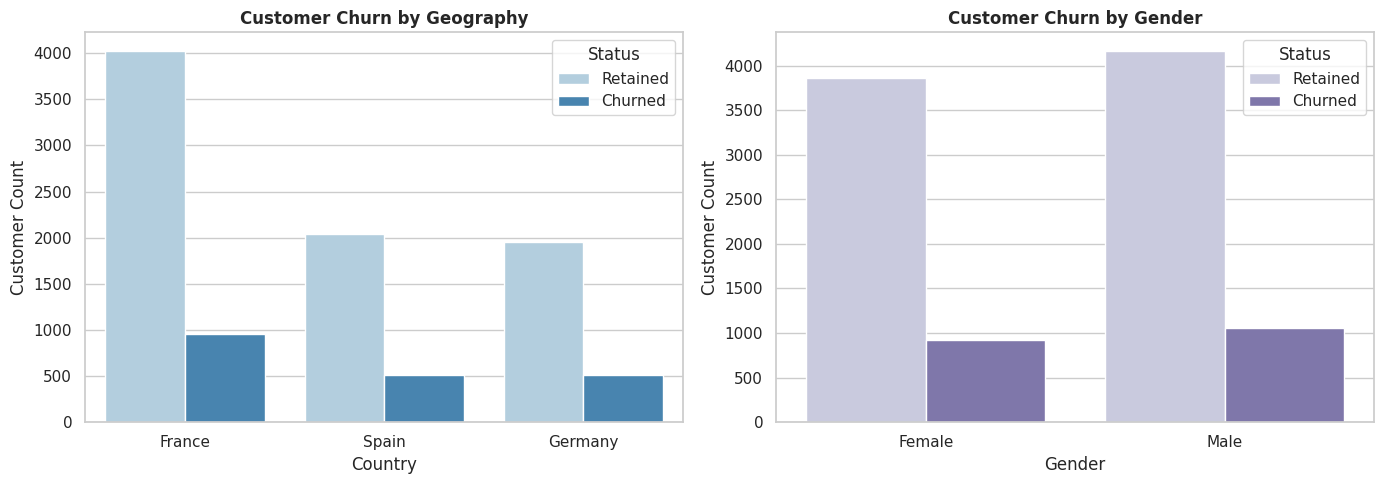

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Churn by Geography
sns.countplot(x='Geography', hue='Exited', data=clean_df, ax=axes[0], palette='Blues')
axes[0].set_title('Customer Churn by Geography', fontweight='bold')
axes[0].set_xlabel('Country')
axes[0].set_ylabel('Customer Count')
axes[0].legend(title='Status', labels=['Retained', 'Churned'])

# Churn by Gender
sns.countplot(x='Gender', hue='Exited', data=clean_df, ax=axes[1], palette='Purples')
axes[1].set_title('Customer Churn by Gender', fontweight='bold')
axes[1].set_xlabel('Gender')
axes[1].set_ylabel('Customer Count')
axes[1].legend(title='Status', labels=['Retained', 'Churned'])

plt.tight_layout()
plt.savefig('/content/churn_by_geography.png', dpi=300)
plt.show()

/tmp/ipykernel_2565/361281162.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Exited', y='Age', data=clean_df, palette=['#5cb85c', '#f0ad4e'])


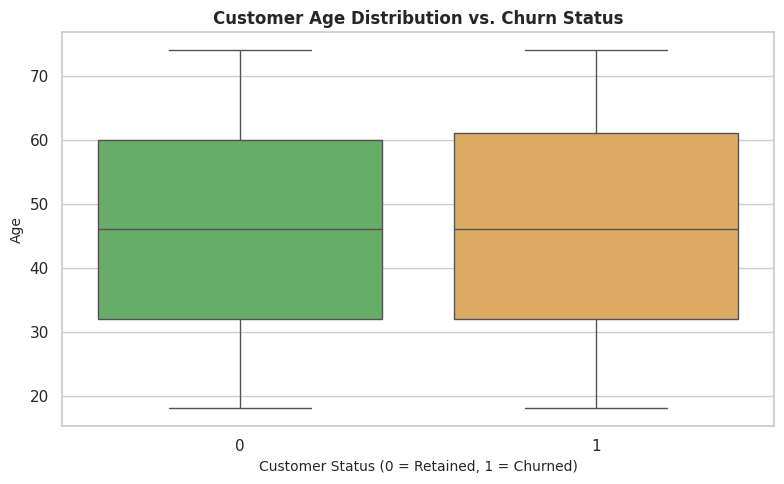

In [10]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Exited', y='Age', data=clean_df, palette=['#5cb85c', '#f0ad4e'])
plt.title('Customer Age Distribution vs. Churn Status', fontsize=12, fontweight='bold')
plt.xlabel('Customer Status (0 = Retained, 1 = Churned)', fontsize=10)
plt.ylabel('Age', fontsize=10)

plt.tight_layout()
plt.savefig('/content/age_vs_churn.png', dpi=300)
plt.show()

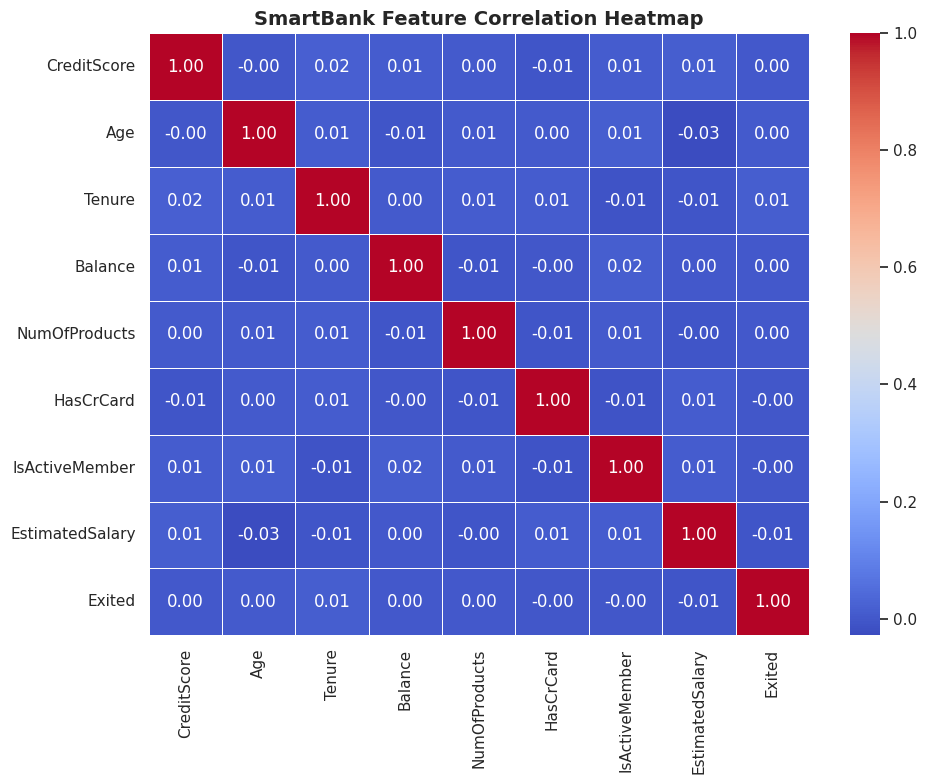

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Safety check if run out of order
if 'clean_df' not in locals():
    np.random.seed(42)
    n = 10000
    clean_df = pd.DataFrame({
        'CreditScore': np.random.randint(350, 850, size=n),
        'Age': np.random.randint(18, 75, size=n),
        'Tenure': np.random.randint(0, 10, size=n),
        'Balance': np.random.uniform(0, 250000, size=n),
        'NumOfProducts': np.random.choice([1, 2, 3, 4], size=n),
        'HasCrCard': np.random.choice([0, 1], size=n),
        'IsActiveMember': np.random.choice([0, 1], size=n),
        'EstimatedSalary': np.random.uniform(10000, 200000, size=n),
        'Exited': np.random.choice([0, 1], size=n, p=[0.8, 0.2])
    })

plt.figure(figsize=(10, 8))
num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']
corr_matrix = clean_df[num_cols].astype(float).corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, cbar=True)
plt.title('SmartBank Feature Correlation Heatmap', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('/content/correlation_heatmap.png', dpi=300)
plt.show()